In [12]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, TensorDataset

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [2]:
torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [3]:
def image_normalization(tensor):
    mean = tensor.mean()
    std = tensor.std()

    return (tensor - mean) / (std + 1e-8)
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),

    transforms.Lambda(image_normalization)
])

train_dataset = ImageFolder(
    root = "DATASETS/IMAGE_CLASSIFICATION/team_10/team_10/train",
    transform= transform
)

test_dataset = ImageFolder(
    root = "DATASETS/IMAGE_CLASSIFICATION/team_10/team_10/test",
    transform= transform
)



In [4]:
class Config:
    BATCH_SIZE = 32
    NUM_CLASSES = len(train_dataset.classes)
    EPOCHS = [10, 100, 1000]
    LR = [0.0001, 0.001, 0.01]

config = Config

In [5]:
train_loader = DataLoader(train_dataset, batch_size=config.BATCH_SIZE, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=config.BATCH_SIZE, shuffle=False, pin_memory=True)

In [6]:
class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=4, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),

            nn.AvgPool2d(kernel_size=2, stride=2),

            nn.Conv2d(in_channels=4, out_channels=8, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),

            nn.AvgPool2d(kernel_size=2, stride=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(8 * 56 * 56, num_classes)
        )

        self.model = nn.Sequential(
            self.features,
            self.classifier
        )
    
    def forward(self, x):
        return self.model(x)

In [7]:
customCNN = CustomCNN(num_classes=config.NUM_CLASSES).to(device)

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(customCNN.parameters(), lr=config.LR[0], weight_decay=1e-4)

train_loss = []
train_accuracies = []

epochs = config.EPOCHS[0]

def train_CNN(model=customCNN, loader=train_loader):

    print("------------------------ TRAINING CNN ------------------------ \n")

    for epoch in range(epochs):
        model.train()
        curr_loss = 0.0
        correct = 0
        total = 0

        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            curr_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        
        epoch_loss = curr_loss / len(loader)
        epoch_acc = 100 * correct / total

        train_loss.append(epoch_loss)
        train_accuracies.append(epoch_acc)

        print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}, Acc: {epoch_acc:.2f}%")

    print("------------------------ TRAINING COMPLETE ------------------------\n")

train_CNN()

------------------------ TRAINING CNN ------------------------ 

Epoch [1/10] - Loss: 1.5298, Acc: 32.40%
Epoch [2/10] - Loss: 1.3222, Acc: 47.14%
Epoch [3/10] - Loss: 1.2011, Acc: 53.26%
Epoch [4/10] - Loss: 1.1026, Acc: 59.09%
Epoch [5/10] - Loss: 1.0293, Acc: 62.97%
Epoch [6/10] - Loss: 0.9479, Acc: 66.80%
Epoch [7/10] - Loss: 0.8869, Acc: 69.63%
Epoch [8/10] - Loss: 0.8225, Acc: 71.86%
Epoch [9/10] - Loss: 0.7747, Acc: 73.74%
Epoch [10/10] - Loss: 0.7185, Acc: 76.06%
------------------------ TRAINING COMPLETE ------------------------



In [9]:
def evaluate_model(model, loader, dataset_name="Test"):
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            output = model(images)
            _, predicted = torch.max(output.data, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    accuracy = 100 * correct / total
    print(f"Accuracy on {dataset_name} set: {accuracy:.2f}%")

    return all_preds, all_labels

In [10]:
print("------------------------ EVALUATING CNN ------------------------")
preds, targets = evaluate_model(customCNN, test_loader, "Test")

------------------------ EVALUATING CNN ------------------------
Accuracy on Test set: 52.00%


----------------- PERFORMANCE -----------------

              precision    recall  f1-score   support

   n01560419       0.37      0.38      0.37       140
   n01582220       0.47      0.55      0.51       140
   n01592084       0.47      0.30      0.37       140
   n01753488       0.57      0.89      0.69       140
   n01773157       0.81      0.49      0.61       140

    accuracy                           0.52       700
   macro avg       0.54      0.52      0.51       700
weighted avg       0.54      0.52      0.51       700



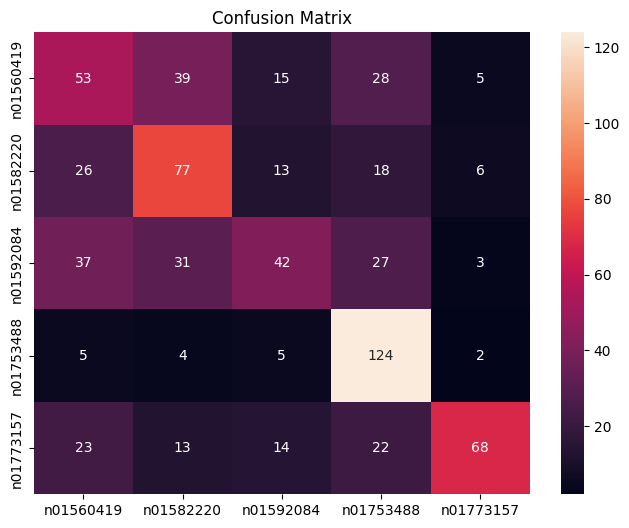

In [17]:
print(f"----------------- PERFORMANCE -----------------\n")
print(classification_report(targets, preds, target_names=train_dataset.classes))

cm = confusion_matrix(targets, preds)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.title("Confusion Matrix")
plt.show()

Dropout decreased accuracy